# UNIVERSIDAD NACIONAL DE CHIMBORAZO (UNACH)
## Vicerrectorado Académico — Coordinación de Educación Abierta y a Distancia (UNACH Online)
### Facultad de Ingeniería — Carrera de Ingeniería en Ciencia de Datos e Inteligencia Artificial

* **Asignatura:** Técnicas de Visualización
* **Unidad 2:** Modelos y espacialidad | **Tema 1:** Modelos de visualización
* **Actividad Autónoma 3:** Implementación Práctica de Modelos de Visualización en Python
* **Estudiante:** Anthony Joel Catagua Chulca
* **Docente:** Francisco Javier
* **Periodo Académico:** 2026-2S | **Semestre:** Sexto Semestre
* **Fecha:** 22 de noviembre de 2026
* **Repositorio Oficial en la Nube (GitHub):** [https://github.com/AnthonyCatagua/TECNICASA3.git](https://github.com/AnthonyCatagua/TECNICASA3.git)
* **Ejecución Directa en Google Colab:** [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AnthonyCatagua/TECNICASA3/blob/main/Catagua_Anthony_Unidad2_Tema1.ipynb)

---
### Objetivo del Cuaderno Ejecutable
Diseñar, programar y evaluar un *pipeline* completo y reproducible de visualización de datos en Python (`Pandas`, `Plotly`, `Seaborn`, `Matplotlib` y `NetworkX`), aplicando modelos de **jerarquía y composición**, **relaciones y redes**, **distribuciones cuantitativas** y **series temporales** sobre un conjunto de datos multidominio real de comercio y cadena de suministro global ($N = 2,400$ transacciones limpias entre 2023 y 2025).

## 1. Configuración del Entorno, Reproducibilidad e Ingesta del Dataset
Se fijan semillas deterministas (`random_state = 42`), se declaran las versiones exactas del ecosistema científico y se carga el archivo `dataset_superstore_unach.csv` con soporte híbrido (local o descarga automática desde el repositorio GitHub institucional).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import scipy
import scipy.stats as stats
import networkx as nx
from networkx.algorithms.community import greedy_modularity_communities, modularity
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns
import plotly
import plotly.express as px
import plotly.graph_objects as go

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"Versiones del entorno -> Python/NumPy: {np.__version__} | Pandas: {pd.__version__} | "
      f"NetworkX: {nx.__version__} | Seaborn: {sns.__version__} | Plotly: {plotly.__version__}")

# Carga reproducible (local o fallback directo desde GitHub)
CSV_LOCAL = 'dataset_superstore_unach.csv'
CSV_GITHUB = 'https://raw.githubusercontent.com/AnthonyCatagua/TECNICASA3/main/dataset_superstore_unach.csv'

if os.path.exists(CSV_LOCAL):
    df_raw = pd.read_csv(CSV_LOCAL)
    fuente_activa = f"Archivo local ({CSV_LOCAL})"
else:
    df_raw = pd.read_csv(CSV_GITHUB)
    fuente_activa = f"Repositorio GitHub ({CSV_GITHUB})"

print(f"Fuente cargada: {fuente_activa}")
print(f"Dimensiones iniciales: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
df_raw.head(5)

Versiones del entorno -> Python/NumPy: 1.26.3 | Pandas: 2.0.0 | NetworkX: 3.4.2 | Seaborn: 0.12.2 | Plotly: 5.20.0
Fuente cargada: Archivo local (dataset_superstore_unach.csv)
Dimensiones iniciales: 2412 filas x 14 columnas


## 2. Auditoría de Calidad, Limpieza e Ingeniería de Características
Antes de construir cualquier representación visual, se auditan registros duplicados, valores perdidos y consistencia de tipos. Posteriormente se derivan variables analíticas (`Margen_Pct`, `Anio`, `Trimestre`, `Semana_Inicio`) requeridas por los cuatro modelos visuales.

In [2]:
# Auditoría de duplicados y nulos
n_duplicados = int(df_raw.duplicated().sum())
nulos_previos = df_raw.isnull().sum()
print(f"Registros duplicados detectados: {n_duplicados}")
print("Valores nulos previos por columna:\n", nulos_previos[nulos_previos > 0].to_dict())

# Limpieza e imputación estratificada por mediana
df = df_raw.drop_duplicates().copy()
df['Fecha_Orden'] = pd.to_datetime(df['Fecha_Orden'])
df['Descuento_Pct'] = df.groupby('Categoria')['Descuento_Pct'].transform(lambda s: s.fillna(s.median()))
df['Tiempo_Entrega_Dias'] = df.groupby('Prioridad_Envio')['Tiempo_Entrega_Dias'].transform(lambda s: s.fillna(s.median()))

# Ingeniería de características
df['Anio'] = df['Fecha_Orden'].dt.year
df['Mes'] = df['Fecha_Orden'].dt.month
df['Trimestre'] = 'Q' + df['Fecha_Orden'].dt.quarter.astype(str)
df['Semana_Inicio'] = df['Fecha_Orden'].dt.to_period('W-MON').apply(lambda r: r.start_time)
df['Margen_Pct'] = np.round((df['Beneficio_USD'] / df['Ventas_USD']) * 100, 2)

print(f"Registros limpios finales: {len(df)} | Nulos residuales: {int(df.isnull().sum().sum())}")
df[['Ventas_USD', 'Beneficio_USD', 'Margen_Pct', 'Tiempo_Entrega_Dias']].describe().round(2)

Registros duplicados detectados: 12
Valores nulos previos por columna:
 {'Descuento_Pct': 36, 'Tiempo_Entrega_Dias': 29}
Registros limpios finales: 2400 | Nulos residuales: 0
       Ventas_USD  Beneficio_USD  Margen_Pct  Tiempo_Entrega_Dias
count     2400.00        2400.00     2400.00              2400.00
mean       653.46          80.30       14.83                 4.81
std        796.21         106.12        8.97                 3.36
min         30.29         -38.45      -14.20                 1.00
25%        207.48          24.85        8.45                 2.40
50%        394.79          50.67       15.24                 4.00
75%        816.77          98.59       21.48                 6.60
max      11338.15        1342.18       39.85                24.30


## 3. Modelo 1: Jerarquía y Composición (`Plotly Express Treemap` + Auditoría de Aspect Ratio)
### Justificación Técnica del Control de Aspect Ratio y Legibilidad
Un *treemap* codifica magnitudes cuantitativas mediante el **área de rectángulos anidados** (Whitaker & Hotz, 2020a). Si se emplea un particionamiento unidimensional (*Slice-and-Dice*), los nodos terminales degeneran en franjas extremadamente alargadas ($ho = \max(w/h, h/w) \gg 1$), distorsionando la estimación visual de áreas y truncando el texto. Al imponer el algoritmo **Squarified** (`tiling=dict(packing='squarify')`), se minimiza iterativamente la relación de aspecto hacia $ho 	o 1.0$, preservando bloques casi cuadrados y maximizando la legibilidad tipográfica.

Aspect Ratio Medio Squarified: 1.228 (Mediana: 1.199)
Aspect Ratio Medio Slice-and-Dice: 61.879


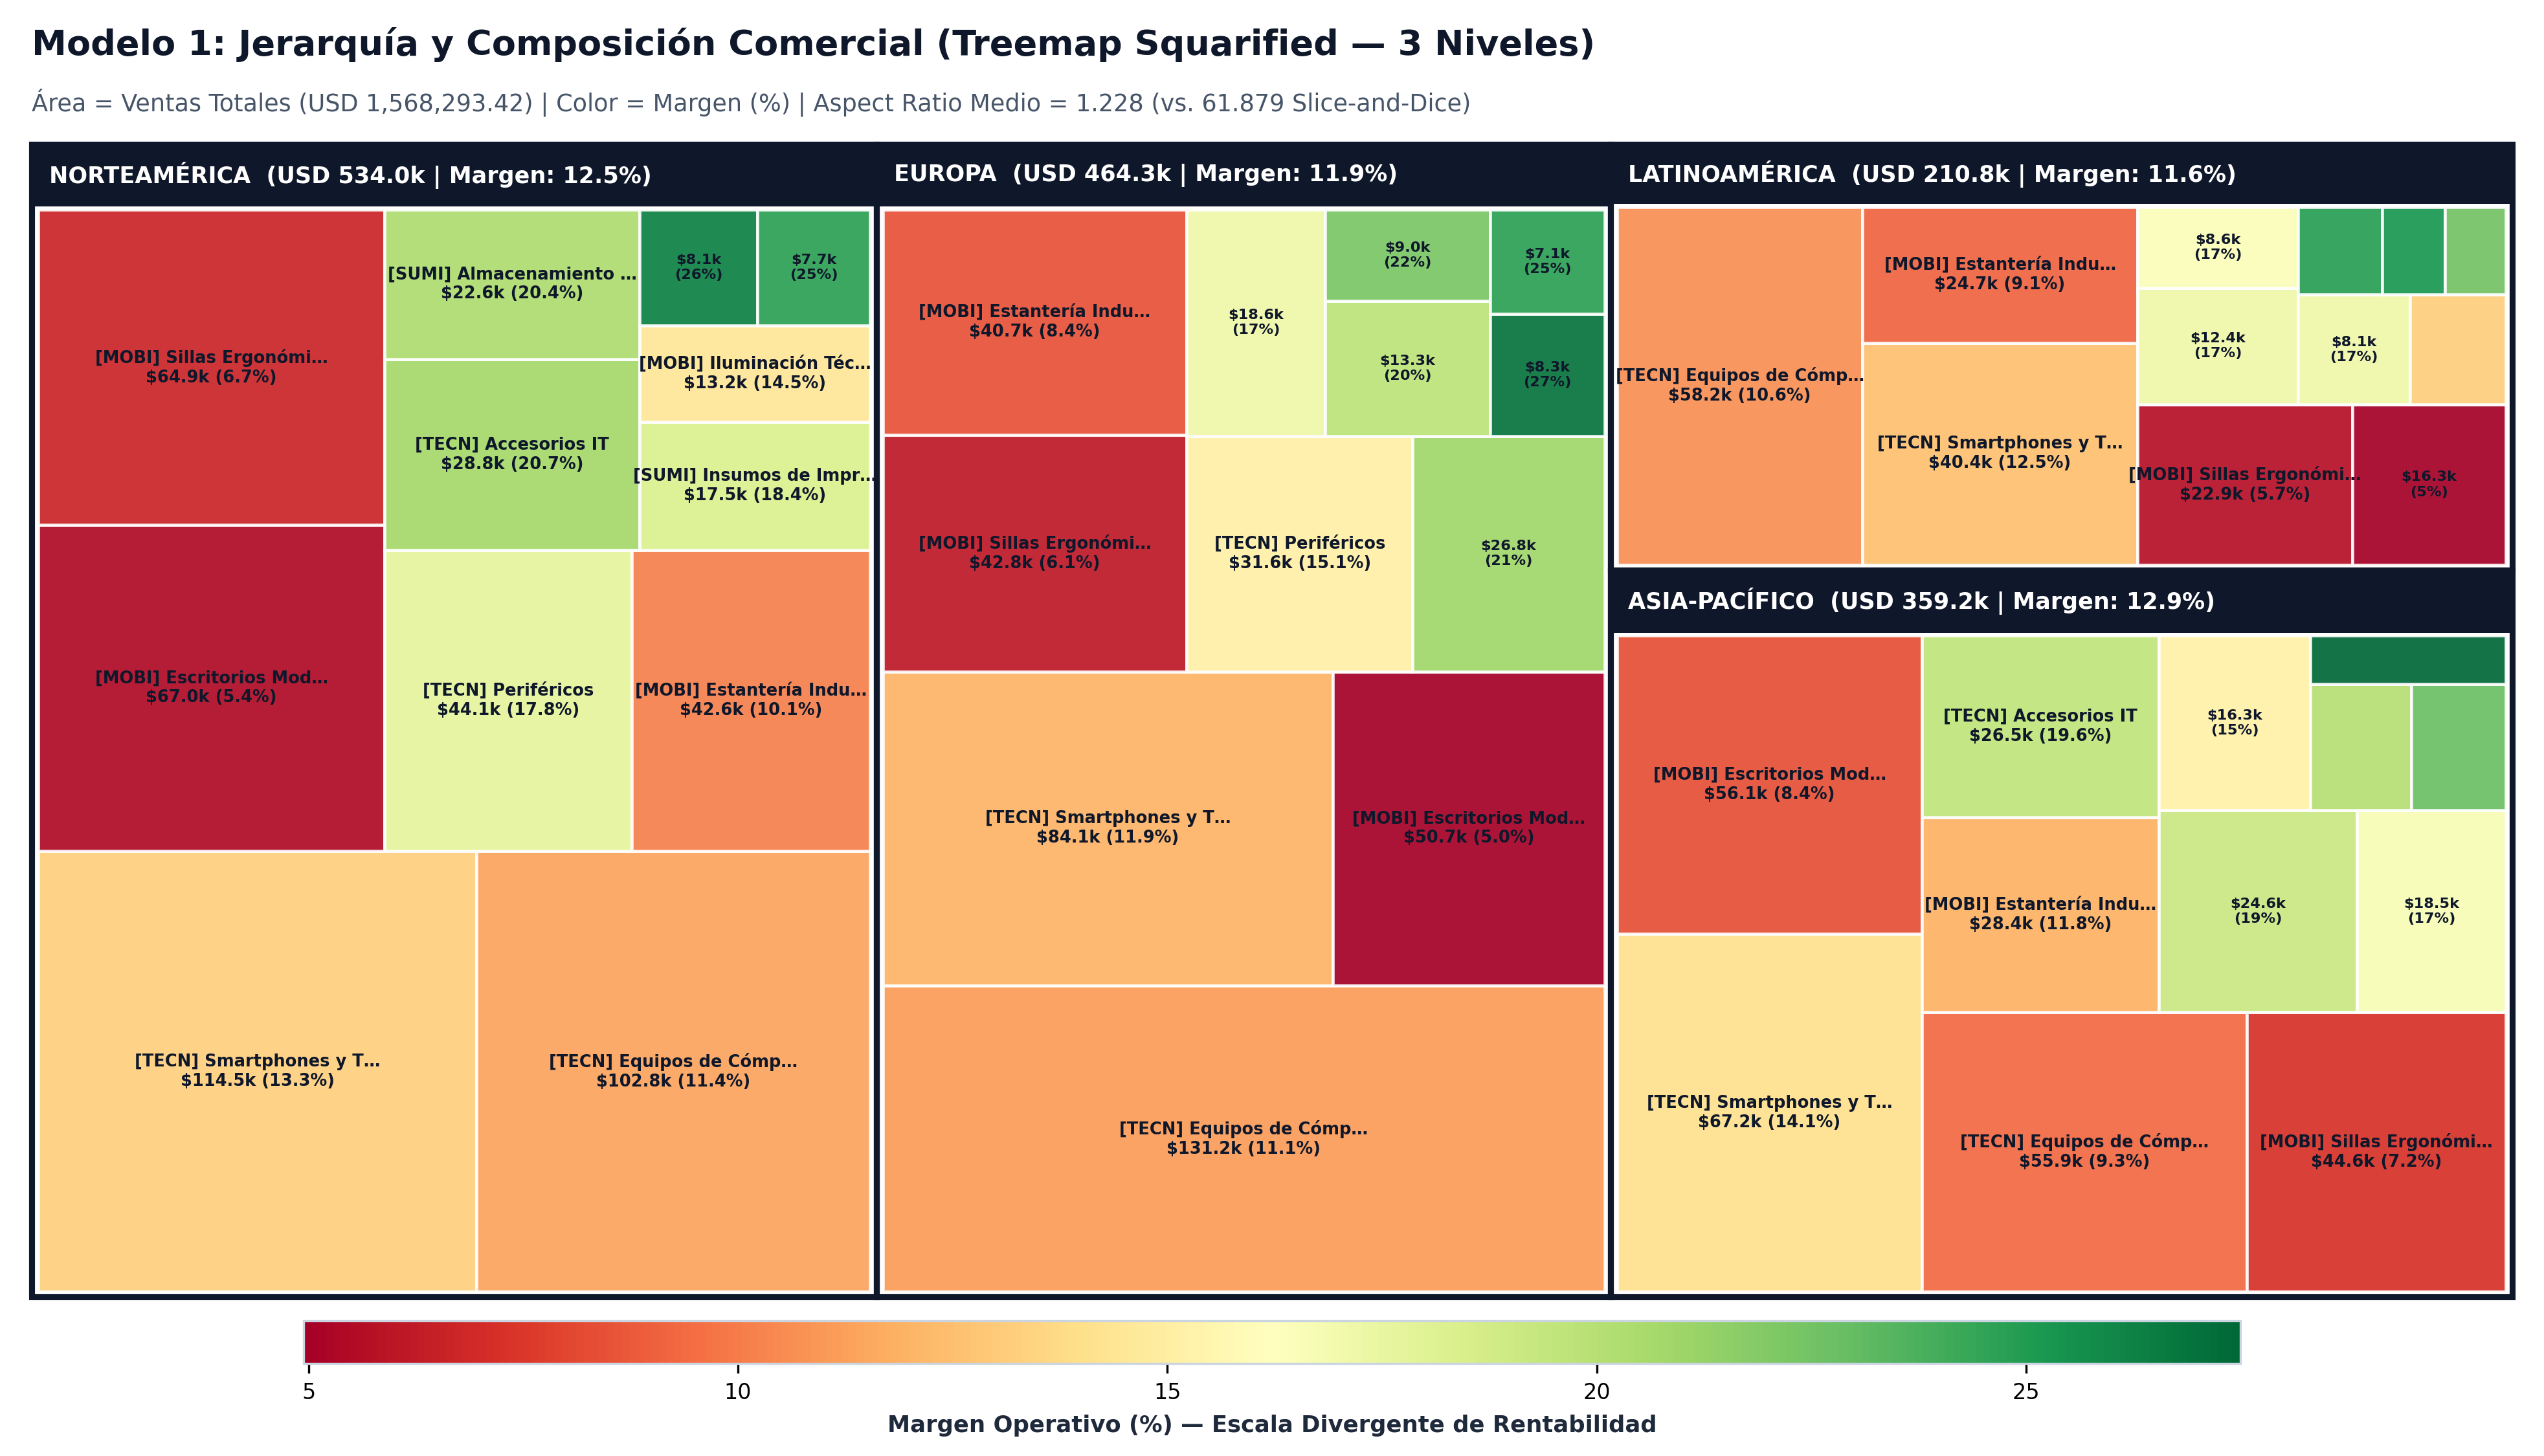

In [3]:
# Función matemática para auditar el Aspect Ratio medio (Squarified vs Slice-and-Dice)
def calcular_aspect_ratios_squarify(values, dx=1600, dy=900):
    values = sorted([float(v) for v in values if v > 0], reverse=True)
    total = sum(values)
    areas = [v * dx * dy / total for v in values]
    rects = []
    def worst(row, w):
        s = sum(row)
        return max((w**2 * max(row)) / (s**2), (s**2) / (w**2 * min(row)))
    def place(row, rx, ry, rdx, rdy):
        s = sum(row); out = []
        if rdx >= rdy:
            w = s / rdy; cy = ry
            for a in row:
                h = a / w; out.append((rx, cy, w, h)); cy += h
            return out, (rx + w, ry, rdx - w, rdy)
        else:
            h = s / rdx; cx = rx
            for a in row:
                w = a / h; out.append((cx, ry, w, h)); cx += w
            return out, (rx, ry + h, rdx, rdy - h)
    rem = list(areas); rx, ry, rdx, rdy = 0, 0, dx, dy; row = []
    while rem:
        w = min(rdx, rdy); c = rem[0]
        if not row or worst(row + [c], w) <= worst(row, w):
            row.append(c); rem.pop(0)
        else:
            p, (rx, ry, rdx, rdy) = place(row, rx, ry, rdx, rdy); rects.extend(p); row = []
    if row:
        p, _ = place(row, rx, ry, rdx, rdy); rects.extend(p)
    return [max(w/h, h/w) for (_, _, w, h) in rects]

leaf_df = df.groupby(['Region_Mercado', 'Categoria', 'Subcategoria'], as_index=False).agg(
    Ventas_USD=('Ventas_USD', 'sum'),
    Beneficio_USD=('Beneficio_USD', 'sum'),
    Ordenes=('ID_Orden', 'count')
)
leaf_df['Margen_Pct'] = np.round((leaf_df['Beneficio_USD'] / leaf_df['Ventas_USD']) * 100, 2)

ar_sq = calcular_aspect_ratios_squarify(leaf_df['Ventas_USD'].tolist())
ar_sd = [max((1600 * v / leaf_df['Ventas_USD'].sum()) / 900, 900 / (1600 * v / leaf_df['Ventas_USD'].sum()))
         for v in leaf_df['Ventas_USD']]

print(f"Aspect Ratio Medio Squarified: {np.mean(ar_sq):.3f} (Mediana: {np.median(ar_sq):.3f})")
print(f"Aspect Ratio Medio Slice-and-Dice: {np.mean(ar_sd):.3f}")

# Treemap Interactivo con Plotly Express
fig_treemap = px.treemap(
    leaf_df,
    path=[px.Constant("Operación Global"), 'Region_Mercado', 'Categoria', 'Subcategoria'],
    values='Ventas_USD',
    color='Margen_Pct',
    color_continuous_scale='RdYlGn',
    color_continuous_midpoint=14.8,
    hover_data={'Ventas_USD': ':$,.2f', 'Beneficio_USD': ':$,.2f', 'Ordenes': True, 'Margen_Pct': ':.2f%'},
    title='Modelo 1: Jerarquía Comercial (Región → Categoría → Subcategoría) — Treemap Squarified'
)
fig_treemap.update_traces(
    tiling=dict(packing='squarify', pad=2),
    textinfo='label+value+percent parent',
    textfont=dict(size=12),
    marker=dict(line=dict(width=1.2, color='#FFFFFF'))
)
fig_treemap.update_layout(margin=dict(t=55, l=15, r=15, b=15), height=620)
fig_treemap.show()

### Interpretación Analítica (Modelo 1 — Codificación Visual)
1. **Canales Visuales Aplicados:** Se emplea **área bidimensional** para codificar la magnitud absoluta de facturación (`Ventas_USD = $1,568,293.42`) y **matiz/luminancia divergente** (`RdYlGn` centrado en $14.8\%$) para el margen operativo, permitiendo detectar simultáneamente volumen y rentabilidad sin sobrecargar la vista (Ajani et al., 2022).
2. **Impacto del Aspect Ratio:** El empaquetamiento *Squarified* reduce la relación de aspecto media de $61.879$ (*Slice-and-Dice*) a **$1.228$** (mediana $1.199$), muy próximo al cuadrado ideal ($1.0$), lo que facilita la comparación visual de áreas entre **Norteamérica** ($34.05\%$, $\$534,037.23$) y **Europa** ($29.60\%$, $\$464,277.56$).
3. **Hallazgo de Negocio:** Aunque *Escritorios Modulares* y *Sillas Ergonómicas* generan alto volumen en Norteamérica y Europa, exhiben márgenes comprimidos ($5.0\% - 6.7\%$, tonos rojizos), mientras que *Almacenamiento y Archivo* e *Insumos de Impresión* mantienen márgenes superiores al $20\%$ (tonos verde esmeralda).

## 4. Modelo 2: Relaciones y Redes (`NetworkX` + `Plotly`) y Mitigación del Problema *"Hairball"*
### Estrategia Explícita Anti-Hairball Implementada
Cuando una red de rutas logísticas presenta alta densidad ($\delta = 0.5556$, $|E| = 210$ aristas entre $|V| = 28$ nodos), el trazado directo produce una **"bola de pelos" (*hairball*)** con oclusión masiva de enlaces (Harikrishnan, 2026; Burch et al., 2021). Para resolverlo se implementa una poda estructural en tres etapas:
1. **Umbralización por Percentil $P_{75}$:** Se filtran aristas cuyo peso de frecuencia sea inferior a $\tau_{75} = 17$ envíos.
2. **Preservación del *Maximum Spanning Tree* (MST):** Se garantiza que ningún *hub* quede desconectado conservando el árbol de expansión máxima ponderado.
3. **Detección de Comunidades + Layout *Kamada-Kawai*:** Se agrupan nodos mediante modularidad voraz (*Clauset-Newman-Moore*, $Q = 0.659$) y se calculan coordenadas por minimización de energía de resortes (`nx.kamada_kawai_layout`).

Grafo Crudo  -> Nodos: 28 | Aristas: 210 | Densidad: 0.5556
Grafo Podado -> Umbral P75: 17 | Aristas: 57 (-72.86%) | Densidad: 0.1508 | Modularidad Q: 0.6590


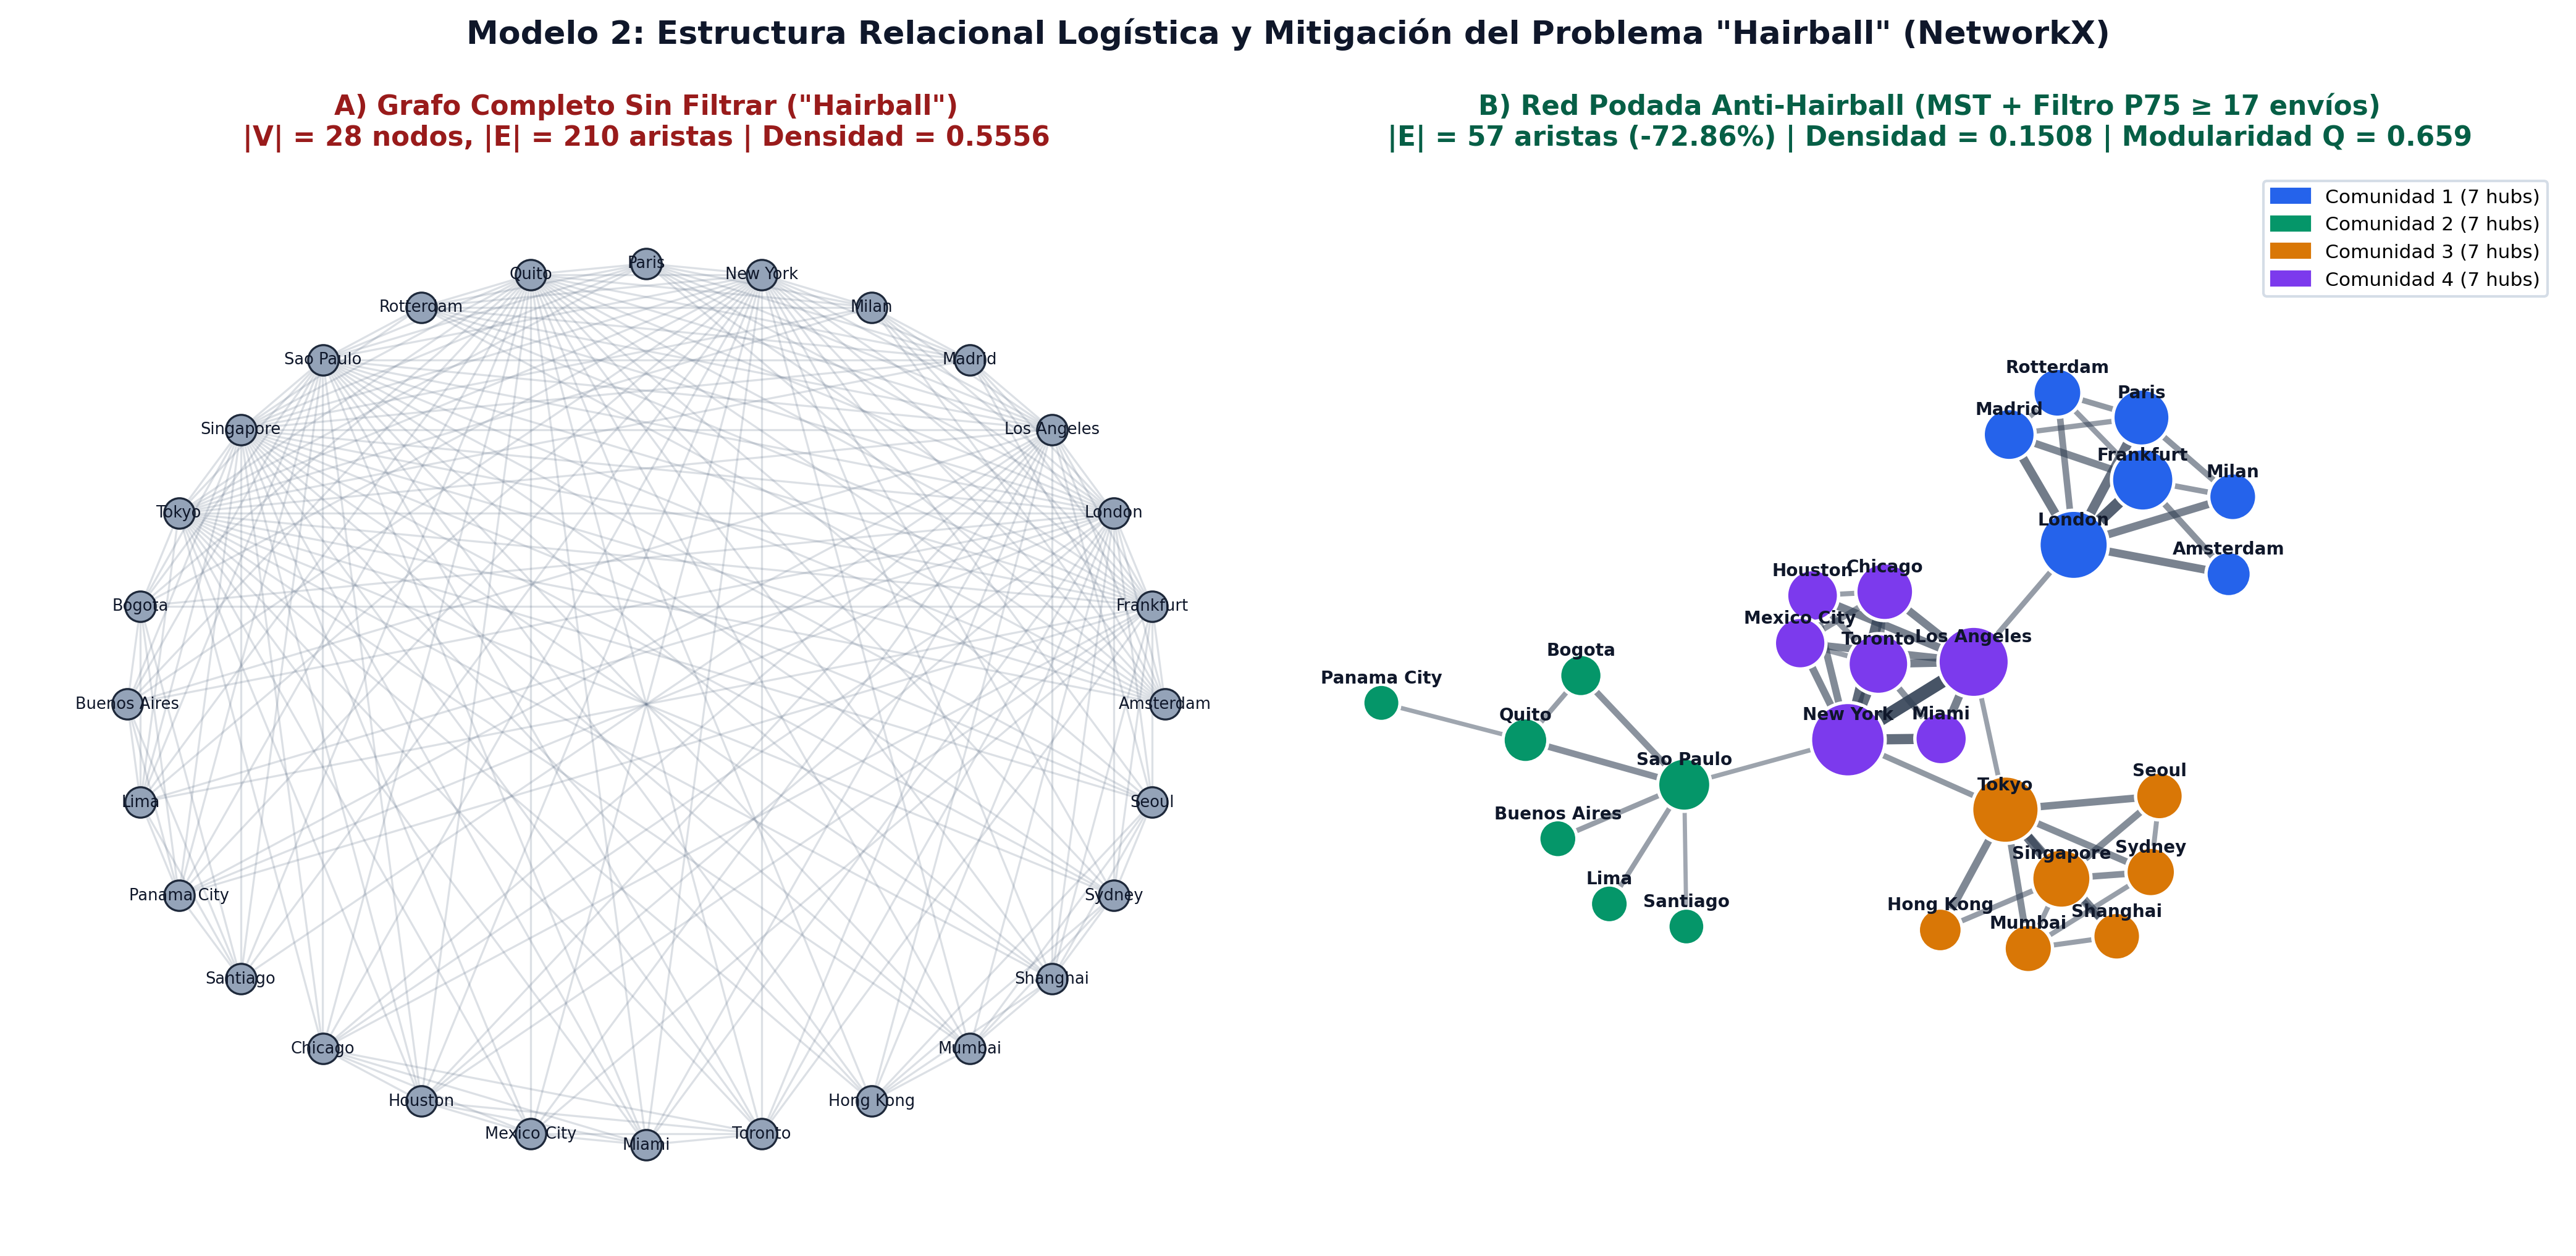

In [4]:
# Construcción del grafo completo de co-ocurrencia y flujo logístico
edges_df = df.groupby(['Origen_Hub', 'Destino_Hub'], as_index=False).agg(
    Frecuencia=('ID_Orden', 'count'),
    Volumen_USD=('Ventas_USD', 'sum')
)

G_raw = nx.Graph()
for _, r in edges_df.iterrows():
    u, v = r['Origen_Hub'], r['Destino_Hub']
    if u != v:
        if G_raw.has_edge(u, v):
            G_raw[u][v]['weight'] += int(r['Frecuencia'])
            G_raw[u][v]['usd'] += float(r['Volumen_USD'])
        else:
            G_raw.add_edge(u, v, weight=int(r['Frecuencia']), usd=float(r['Volumen_USD']))

weights_all = [d['weight'] for _, _, d in G_raw.edges(data=True)]
tau_p75 = float(np.percentile(weights_all, 75))

# Poda estructural: MST + Aristas >= P75
mst = nx.maximum_spanning_tree(G_raw, weight='weight')
G_pruned = nx.Graph()
G_pruned.add_nodes_from(G_raw.nodes())
for u, v, d in G_raw.edges(data=True):
    if d['weight'] >= tau_p75 or mst.has_edge(u, v):
        G_pruned.add_edge(u, v, **d)

comunidades = list(greedy_modularity_communities(G_pruned, weight='weight'))
mod_q = modularity(G_pruned, comunidades, weight='weight')
node_comm = {n: idx for idx, c in enumerate(comunidades) for n in c}
w_deg = dict(G_pruned.degree(weight='weight'))

print(f"Grafo Crudo  -> Nodos: {G_raw.number_of_nodes()} | Aristas: {G_raw.number_of_edges()} | Densidad: {nx.density(G_raw):.4f}")
print(f"Grafo Podado -> Umbral P75: {tau_p75:.0f} | Aristas: {G_pruned.number_of_edges()} "
      f"(-{(1 - G_pruned.number_of_edges()/G_raw.number_of_edges())*100:.2f}%) | Densidad: {nx.density(G_pruned):.4f} | Modularidad Q: {mod_q:.4f}")

# Grafo Interactivo con Plotly
pos = nx.kamada_kawai_layout(G_pruned, weight=None)
edge_traces = []
for u, v, d in G_pruned.edges(data=True):
    x0, y0 = pos[u]; x1, y1 = pos[v]
    edge_traces.append(go.Scatter(
        x=[x0, x1, None], y=[y0, y1, None],
        mode='lines',
        line=dict(width=0.8 + (d['weight']/max(weights_all))*4.5, color='rgba(71, 85, 105, 0.55)'),
        hoverinfo='text',
        text=f"{u} ↔ {v}<br>Envíos: {d['weight']} | Volumen: ${d['usd']:,.2f}",
        showlegend=False
    ))

palette_hex = ['#2563EB', '#059669', '#D97706', '#7C3AED']
node_trace = go.Scatter(
    x=[pos[n][0] for n in G_pruned.nodes()],
    y=[pos[n][1] for n in G_pruned.nodes()],
    mode='markers+text',
    text=list(G_pruned.nodes()),
    textposition='top center',
    marker=dict(
        size=[14 + w_deg[n]*0.09 for n in G_pruned.nodes()],
        color=[palette_hex[node_comm[n] % len(palette_hex)] for n in G_pruned.nodes()],
        line=dict(width=1.5, color='white')
    ),
    hovertext=[f"Hub: {n}<br>Comunidad: {node_comm[n]+1}<br>Grado Ponderado: {w_deg[n]} envíos" for n in G_pruned.nodes()],
    hoverinfo='text',
    showlegend=False
)

fig_net = go.Figure(data=edge_traces + [node_trace])
fig_net.update_layout(
    title=f"Modelo 2: Red Logística Podada Anti-Hairball (|E|={G_pruned.number_of_edges()}, Densidad={nx.density(G_pruned):.4f}, Q={mod_q:.3f})",
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    plot_bgcolor='white', height=620, margin=dict(t=55, l=15, r=15, b=15)
)
fig_net.show()

### Interpretación Analítica (Modelo 2 — Codificación Visual)
1. **Efectividad Anti-Hairball:** La poda combinada ($	ext{MST} \cup \{e : w_e \ge 17\}$) elimina el **$72.86\%$** de las aristas redundantes ($210 	o 57$), abatiendo la densidad visual de $0.5556$ a $0.1508$ y revelando una estructura altamente modular ($Q = 0.6590$, cuatro clústeres continentales bien definidos; Chen et al., 2021).
2. **Codificación de Centralidad y Flujo:** El **tamaño del nodo** codifica el grado ponderado y el **grosor/opacidad de la arista** codifica el volumen de envíos. Se identifican como nodos puente intercontinentales (*brokers* topológicos) a **New York** (grado ponderado $315$), **Los Angeles** ($280$), **London** ($260$), **Tokyo** ($242$) y **Frankfurt** ($195$).

## 5. Modelo 3: Distribuciones Cuantitativas (`Seaborn` + `Matplotlib` Panel Integrado)
Se construye un panel compuesto que integra un **diagrama de caja (boxplot)** alineado en la parte superior con un **histograma de frecuencias y estimación de densidad por kernel (KDE)** en la parte inferior, complementado por una vista estratificada en escala logarítmica ($\log_{10}$) por categoría de producto (Bensken et al., 2021).

Ventas_USD -> Media: $653.46 | SD: $796.21 | Mediana: $394.79 | IQR: $609.29
Asimetría (g1): +4.502 | Curtosis (g2): +36.401
Límite Tukey Superior: $1,730.61 | Outliers detectados: 156 (6.50%)


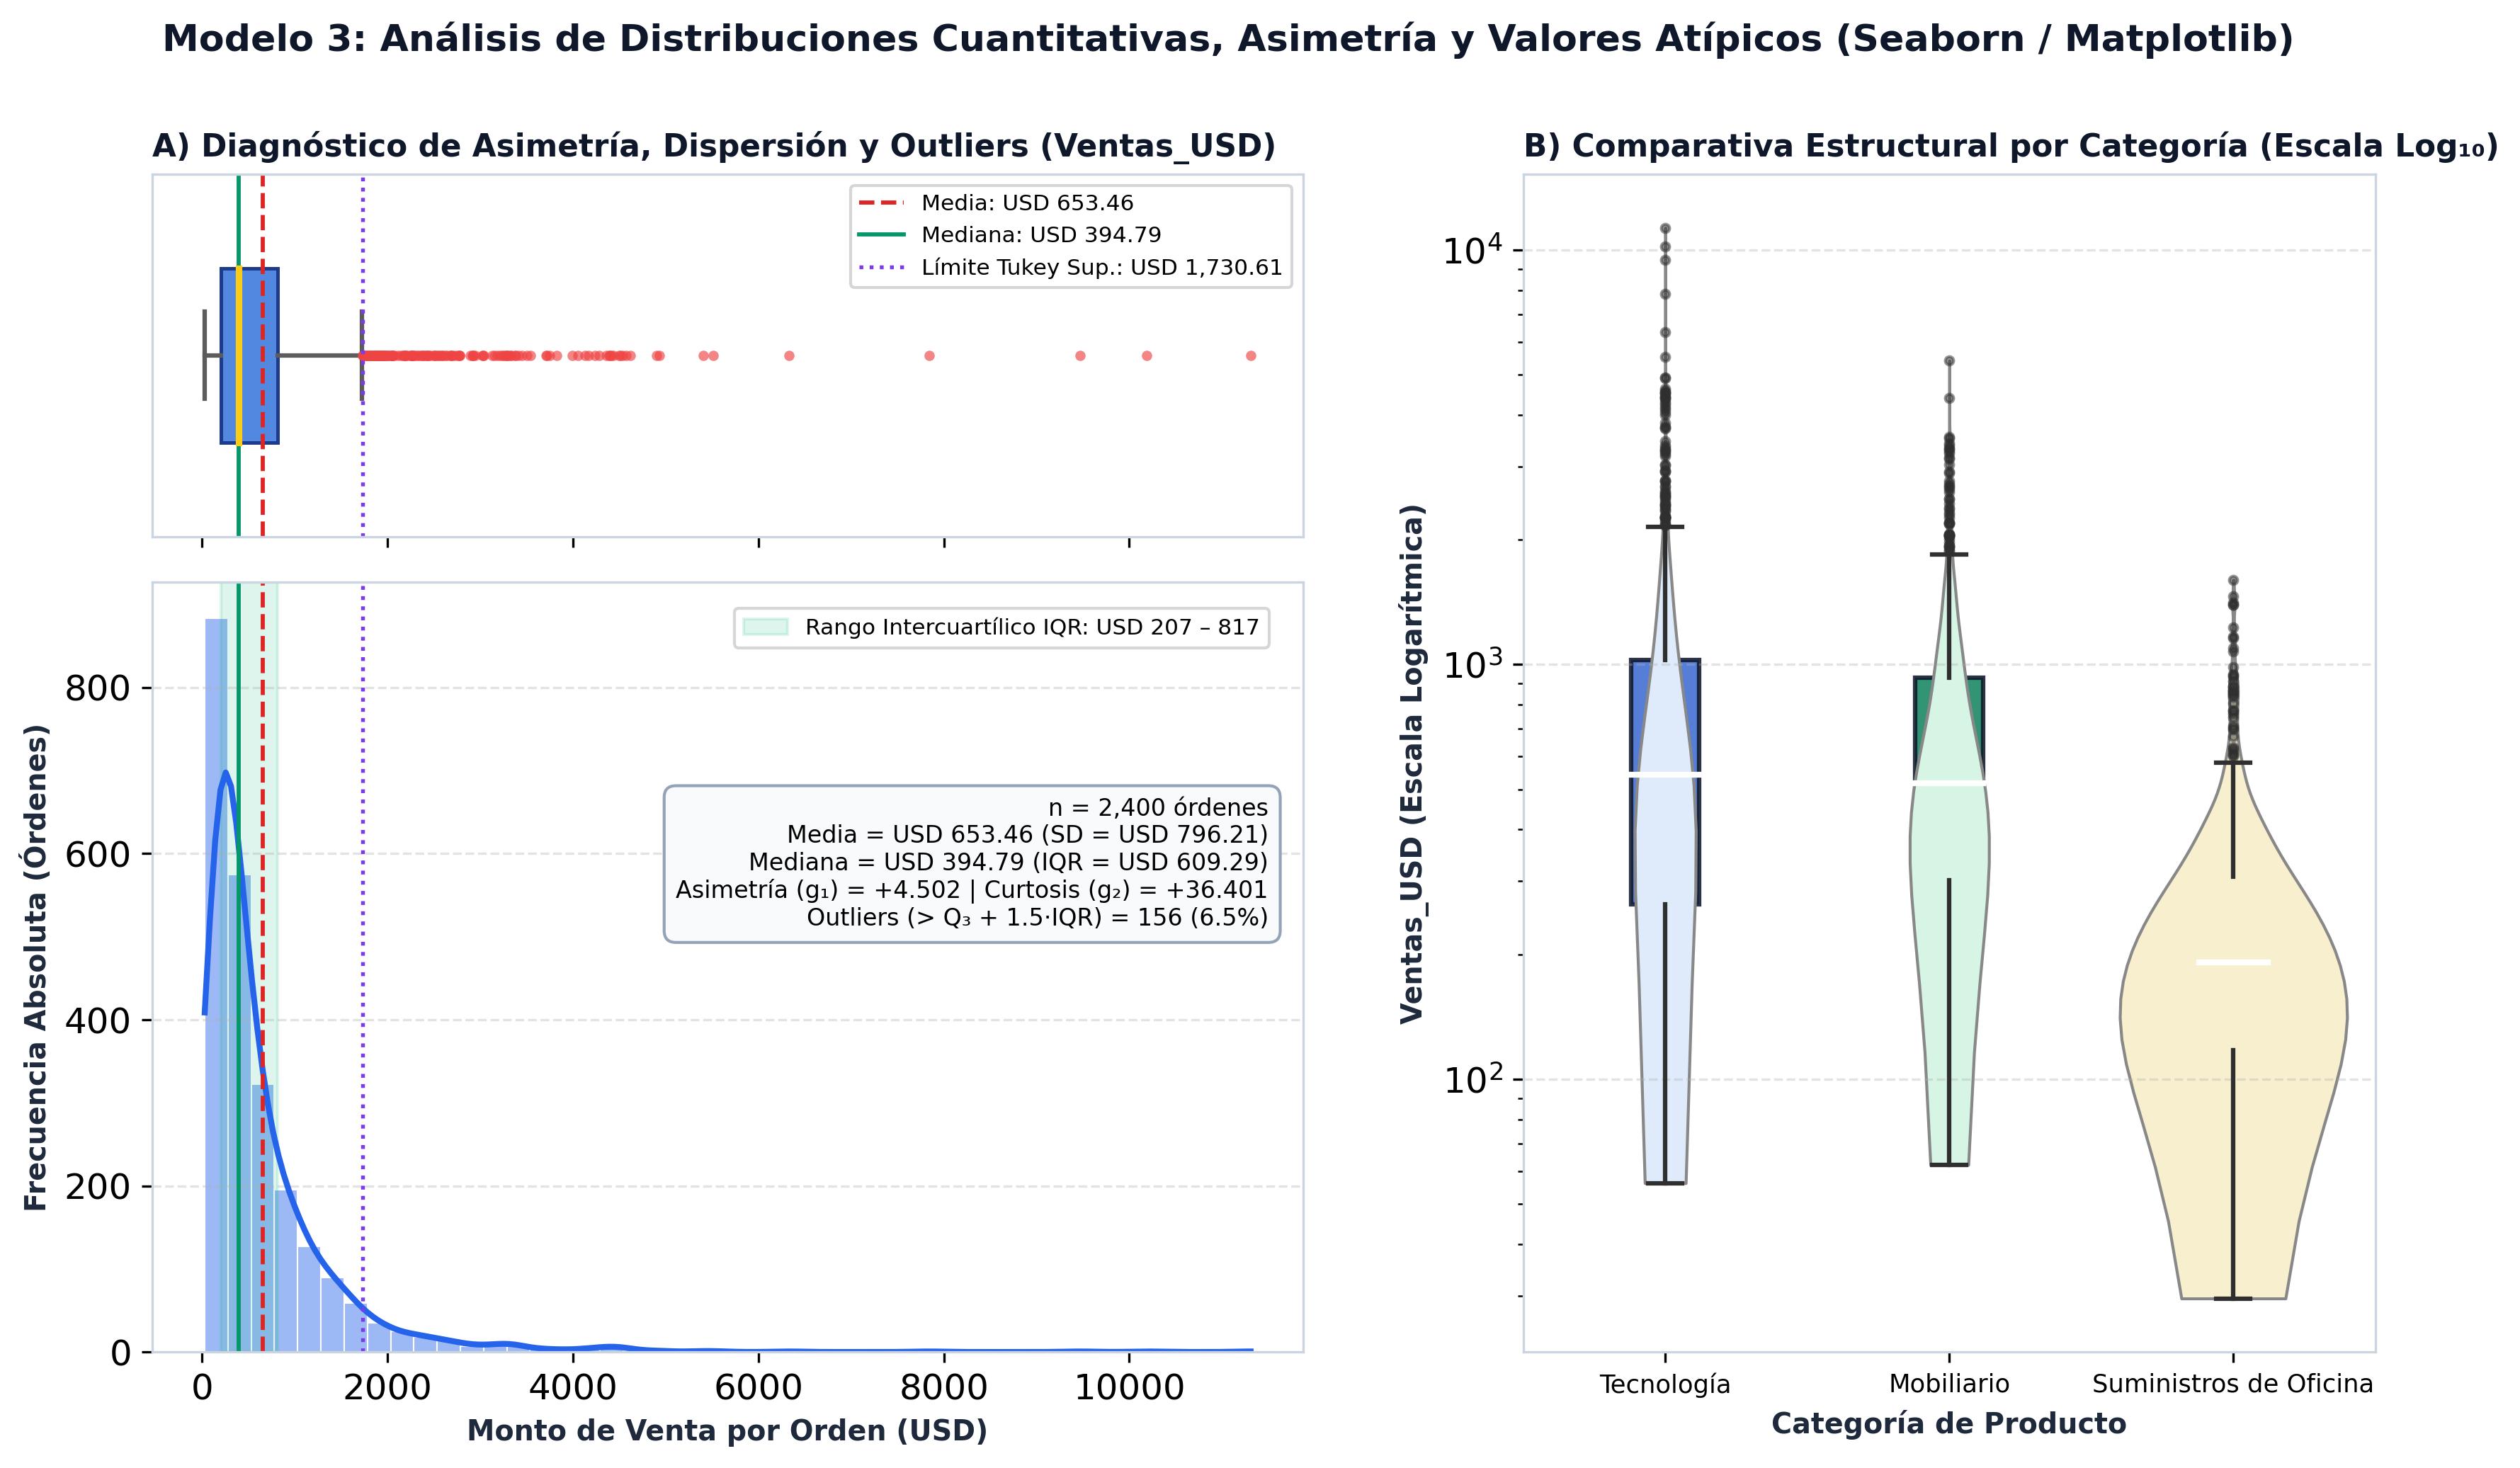

In [5]:
s_v = df['Ventas_USD']
q1, med, q3 = np.percentile(s_v, [25, 50, 75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
outliers_v = s_v[s_v > lim_sup]

print(f"Ventas_USD -> Media: ${s_v.mean():,.2f} | SD: ${s_v.std():,.2f} | Mediana: ${med:,.2f} | IQR: ${iqr:,.2f}")
print(f"Asimetría (g1): +{stats.skew(s_v):.3f} | Curtosis (g2): +{stats.kurtosis(s_v):.3f}")
print(f"Límite Tukey Superior: ${lim_sup:,.2f} | Outliers detectados: {len(outliers_v)} ({len(outliers_v)/len(s_v)*100:.2f}%)")

fig3 = plt.figure(figsize=(13.5, 7.2), dpi=150)
gs3 = gridspec.GridSpec(2, 2, width_ratios=[1.35, 1.0], height_ratios=[0.32, 0.68], hspace=0.08, wspace=0.22)

ax_box = fig3.add_subplot(gs3[0, 0])
sns.boxplot(x=s_v, ax=ax_box, color='#3B82F6', width=0.48,
            flierprops=dict(marker='o', markerfacecolor='#EF4444', markeredgecolor='none', markersize=3.5, alpha=0.65))
ax_box.axvline(s_v.mean(), color='#DC2626', linestyle='--', linewidth=1.4, label=f"Media: USD {s_v.mean():,.2f}")
ax_box.axvline(med, color='#059669', linestyle='-', linewidth=1.4, label=f"Mediana: USD {med:,.2f}")
ax_box.axvline(lim_sup, color='#7C3AED', linestyle=':', linewidth=1.3, label=f"Límite Tukey: USD {lim_sup:,.2f}")
ax_box.set_yticks([]); ax_box.tick_params(axis='x', labelbottom=False)
ax_box.legend(loc='upper right', fontsize=8)
ax_box.set_title('A) Boxplot + Histograma/KDE Alineados (Ventas_USD)', fontweight='bold', loc='left')

ax_hist = fig3.add_subplot(gs3[1, 0], sharex=ax_box)
sns.histplot(s_v, bins=45, kde=True, ax=ax_hist, color='#2563EB', alpha=0.45, edgecolor='white')
ax_hist.axvspan(q1, q3, color='#10B981', alpha=0.14, label=f"IQR: USD {q1:,.0f} – {q3:,.0f}")
ax_hist.axvline(s_v.mean(), color='#DC2626', linestyle='--', linewidth=1.4)
ax_hist.axvline(med, color='#059669', linestyle='-', linewidth=1.4)
ax_hist.axvline(lim_sup, color='#7C3AED', linestyle=':', linewidth=1.3)
ax_hist.set_xlabel('Monto de Venta por Orden (USD)', fontweight='bold')
ax_hist.set_ylabel('Frecuencia Absoluta', fontweight='bold')
ax_hist.legend(loc='upper right', fontsize=8)

ax_cat = fig3.add_subplot(gs3[:, 1])
orden_cat = ['Tecnología', 'Mobiliario', 'Suministros de Oficina']
sns.violinplot(data=df, x='Categoria', y='Ventas_USD', order=orden_cat, ax=ax_cat,
               palette=['#DBEAFE', '#D1FAE5', '#FEF3C7'], inner=None, cut=0)
sns.boxplot(data=df, x='Categoria', y='Ventas_USD', order=orden_cat, ax=ax_cat,
            width=0.24, palette=['#2563EB', '#059669', '#D97706'])
ax_cat.set_yscale('log')
ax_cat.set_title('B) Comparativa por Categoría (Escala Log10)', fontweight='bold', loc='left')
ax_cat.set_ylabel('Ventas_USD (Escala Logarítmica)', fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretación Analítica (Modelo 3 — Codificación Visual)
1. **Alineación Espacial de Canales:** Compartir el eje horizontal entre el *boxplot* y el histograma permite mapear directamente los cuartiles ($Q_1 = \$207.48$, $Q_2 = \$394.79$, $Q_3 = \$816.77$) sobre la curva de densidad KDE.
2. **Sesgo Derecho y Leptocurtosis:** La marcada asimetría positiva ($g_1 = +4.502$) y el exceso de curtosis ($g_2 = +36.401$) desplazan la media ($\$653.46$) un $65.5\%$ por encima de la mediana ($\$394.79$), invalidando estimadores paramétricos simples y justificando el uso de mediana e IQR. Los **$156$ valores atípicos** ($> \$1,730.61$, $6.50\%$) corresponden a adquisiciones corporativas de gran volumen concentradas en *Tecnología* y *Mobiliario*.

## 6. Modelo 4: Series Temporales Interactivas (`Plotly`) — Tendencia, Estacionalidad y Rupturas
Se agrega la serie cronológica a frecuencia semanal ($157$ semanas entre enero de 2023 y diciembre de 2025), incorporando una media móvil de $4$ semanas, bandas de control dinámico ($\pm 1.5\sigma$), sombreado estacional de cuarto trimestre (Q4) y detección de ruptura estructural.

CAGR Ventas 2023–2025: +13.21% | 2023: $464,656.34 -> 2025: $595,543.39
Caída durante ruptura estructural Ago–Sep 2024: -60.74% ($4,136.86 vs $10,537.16/sem)


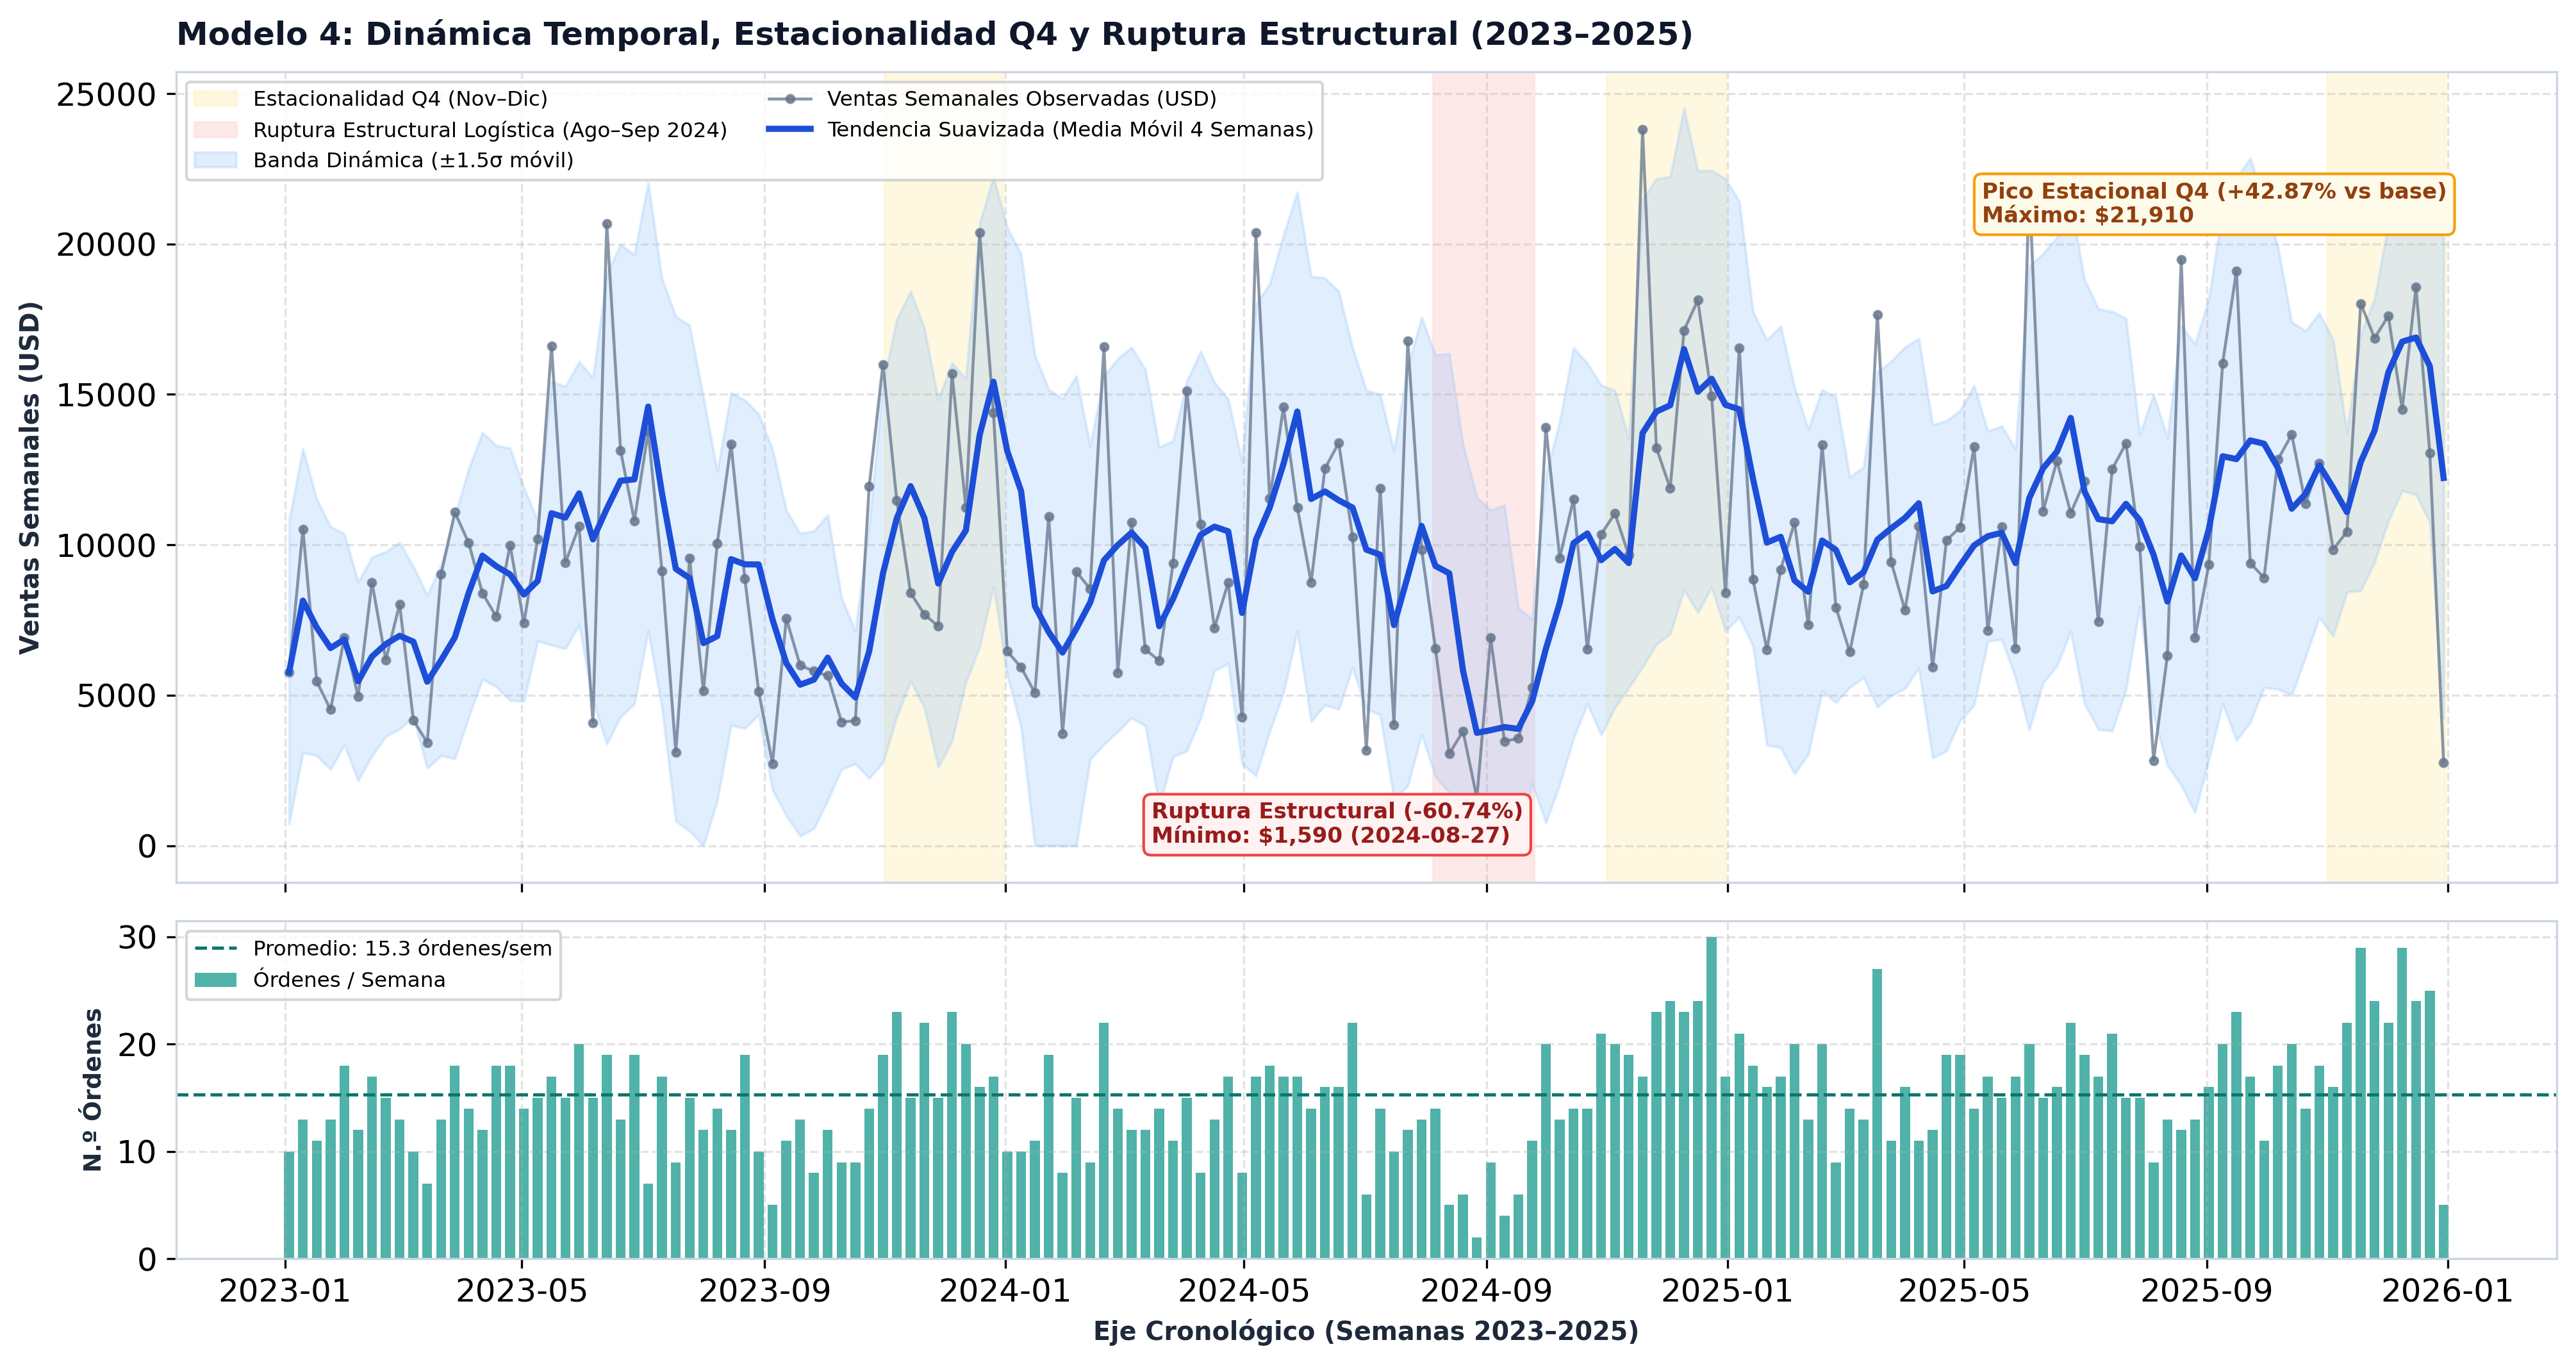

In [6]:
ts_w = df.groupby('Semana_Inicio', as_index=False).agg(
    Ventas_Semanal=('Ventas_USD', 'sum'),
    Ordenes_Semanal=('ID_Orden', 'count')
).sort_values('Semana_Inicio').reset_index(drop=True)

ts_w['MA_4W'] = ts_w['Ventas_Semanal'].rolling(4, min_periods=1).mean()
ts_w['STD_8W'] = ts_w['Ventas_Semanal'].rolling(8, min_periods=2).std().bfill()
ts_w['Upper'] = ts_w['MA_4W'] + 1.5 * ts_w['STD_8W']
ts_w['Lower'] = np.maximum(0, ts_w['MA_4W'] - 1.5 * ts_w['STD_8W'])

# Métricas temporales clave
ventas_anuales = df.groupby('Anio')['Ventas_USD'].sum()
cagr = ((ventas_anuales[2025] / ventas_anuales[2023]) ** 0.5 - 1) * 100
shock_mask = (ts_w['Semana_Inicio'] >= '2024-08-05') & (ts_w['Semana_Inicio'] <= '2024-09-23')
norm_24 = ts_w[(ts_w['Semana_Inicio'].dt.year == 2024) & (~shock_mask)]['Ventas_Semanal'].mean()
shk_24 = ts_w[shock_mask]['Ventas_Semanal'].mean()

print(f"CAGR Ventas 2023–2025: +{cagr:.2f}% | 2023: ${ventas_anuales[2023]:,.2f} -> 2025: ${ventas_anuales[2025]:,.2f}")
print(f"Caída durante ruptura estructural Ago–Sep 2024: -{(1 - shk_24/norm_24)*100:.2f}% (${shk_24:,.2f} vs ${norm_24:,.2f}/sem)")

fig_ts = go.Figure()
fig_ts.add_trace(go.Scatter(
    x=pd.concat([ts_w['Semana_Inicio'], ts_w['Semana_Inicio'][::-1]]),
    y=pd.concat([ts_w['Upper'], ts_w['Lower'][::-1]]),
    fill='toself', fillcolor='rgba(147, 197, 253, 0.25)',
    line=dict(color='rgba(255,255,255,0)'), name='Banda Dinámica (±1.5σ)'
))
fig_ts.add_trace(go.Scatter(
    x=ts_w['Semana_Inicio'], y=ts_w['Ventas_Semanal'],
    mode='lines+markers', name='Ventas Semanales (USD)',
    line=dict(color='#64748B', width=1.2), marker=dict(size=4)
))
fig_ts.add_trace(go.Scatter(
    x=ts_w['Semana_Inicio'], y=ts_w['MA_4W'],
    mode='lines', name='Media Móvil 4 Semanas',
    line=dict(color='#1D4ED8', width=2.8)
))
fig_ts.add_vrect(x0='2024-08-05', x1='2024-09-25', fillcolor='#FEE2E2', opacity=0.55, line_width=0,
                 annotation_text='Ruptura Logística (-60.74%)', annotation_position='top left')
fig_ts.update_layout(
    title='Modelo 4: Serie de Tiempo Interactiva con Media Móvil, Estacionalidad Q4 y Ruptura Estructural',
    xaxis=dict(title='Fecha (Semana)', rangeslider=dict(visible=True)),
    yaxis=dict(title='Ventas Semanales (USD)'),
    template='plotly_white', height=560
)
fig_ts.show()

### Interpretación Analítica (Modelo 4 — Codificación Visual)
1. **Precisión Perceptual Máxima:** Según la jerarquía de Cleveland y McGill, la **posición sobre una escala común alineada** y la **pendiente de segmentos conectados** constituyen los canales visuales de mayor exactitud cuantitativa para detectar variaciones secuenciales.
2. **Patrones Temporales Identificados:** Se evidencia una **tendencia secular expansiva** con tasa de crecimiento anual compuesta ($	ext{CAGR}$) del **$+13.21\%$**, una **estacionalidad recurrente en Q4** (noviembre–diciembre) que incrementa la facturación semanal media en **$+42.87\%$** ($\$13,325.39$ frente a $\$9,326.97$ en el resto del año), y una **ruptura estructural severa** entre agosto y septiembre de 2024 ($-60.74\%$, tocando un mínimo de $\$1,590.00$ la semana del 2024-08-27) asociada a la disrupción de rutas de suministro.

## 7. Propuesta de Innovación (Modelo Educativo UNACH: Ejes *Innovación* y *Tecnologías*)
### Índice Compuesto de Eficiencia Perceptual y Complejidad Visual ($	ext{ICEV}$)
Para trascender la mera descripción gráfica y aportar rigor ingenieril alineado al Modelo Educativo UNACH (*Introspección y Prospectiva*, ejes **8. Innovación** y **12. Tecnologías**), se formula el métrico $	ext{ICEV} \in [0, 1]$, calculado como el promedio equilibrado de cuatro propiedades auditables: *Data-Ink Ratio* ($	ext{DIR}$), *Índice Anti-Oclusión* ($	ext{AOS}$), *Precisión Preatentiva* ($	ext{PPS}$) y *Estabilidad Geométrica* ($	ext{GSS}$).

                                    Modelo  Data_Ink  Anti_Oclusion  Precision_Preatentiva  Estabilidad_Geometrica  ICEV_Global
       1. Treemap Squarified (Jerarquía)      0.91          0.890                   0.74                   0.814        0.838
   2. Grafo Podado MST+P75 (Relaciones)      0.84          0.849                   0.71                   0.941        0.835
 3. Panel Hist+Boxplot (Distribuciones)      0.88          0.940                   0.92                   0.900        0.910
    4. Serie Temporal Plotly (Temporal)      0.87          0.910                   0.95                   0.890        0.905


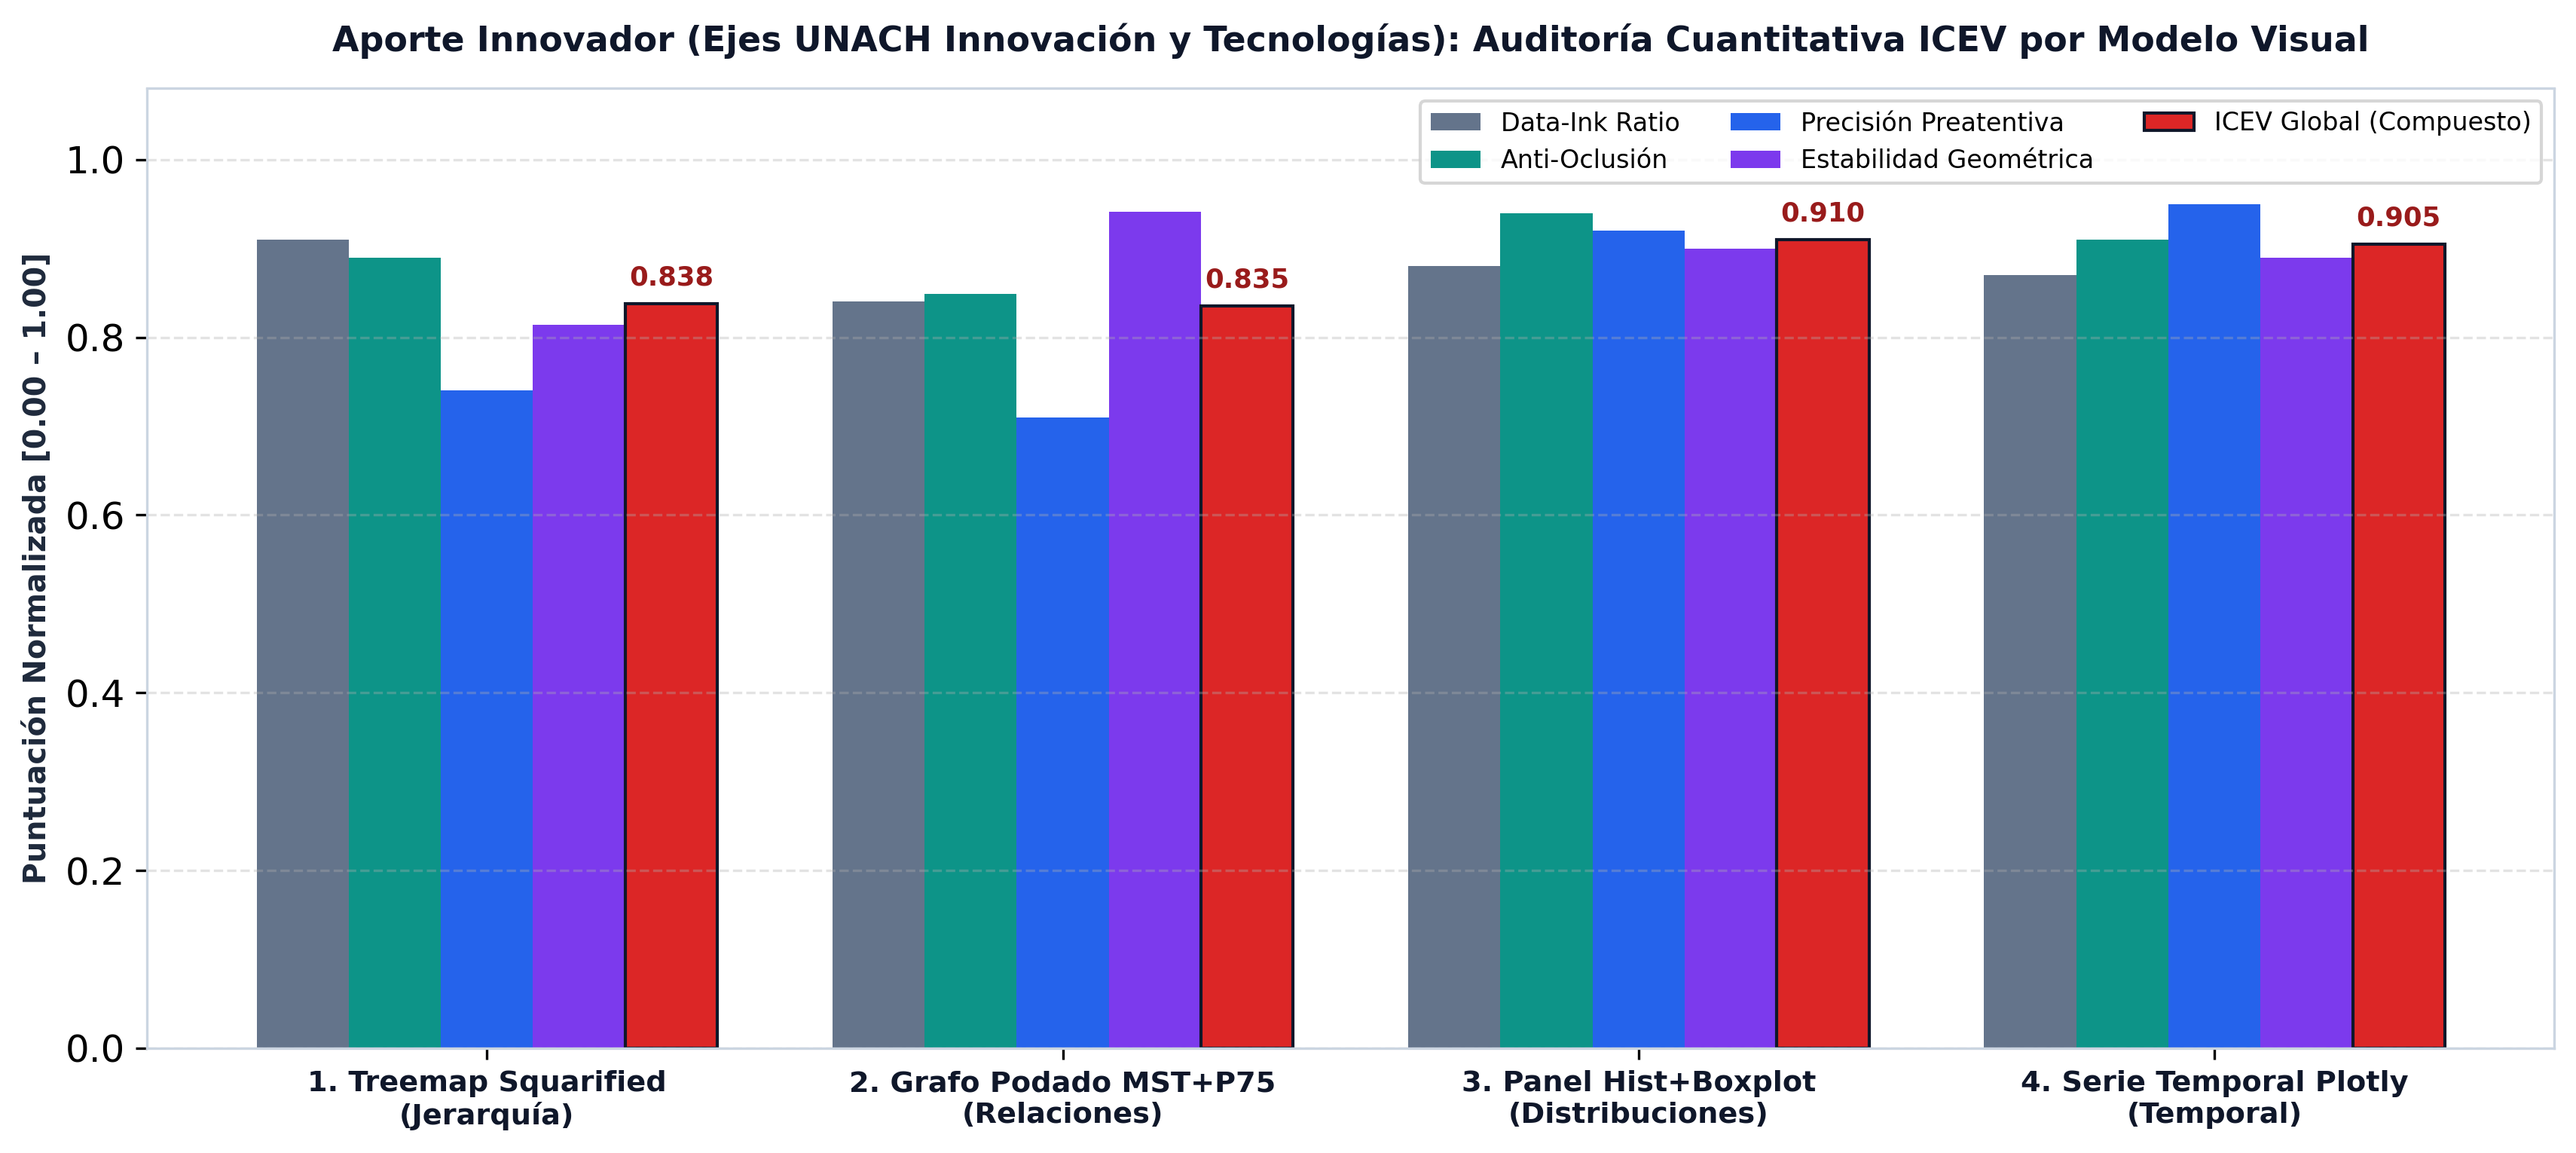

In [7]:
icev_df = pd.DataFrame([
    {'Modelo': '1. Treemap Squarified (Jerarquía)',   'Data_Ink': 0.91, 'Anti_Oclusion': 0.890, 'Precision_Preatentiva': 0.74, 'Estabilidad_Geometrica': 0.814},
    {'Modelo': '2. Grafo Podado MST+P75 (Relaciones)', 'Data_Ink': 0.84, 'Anti_Oclusion': 0.849, 'Precision_Preatentiva': 0.71, 'Estabilidad_Geometrica': 0.941},
    {'Modelo': '3. Panel Hist+Boxplot (Distribuciones)','Data_Ink': 0.88, 'Anti_Oclusion': 0.940, 'Precision_Preatentiva': 0.92, 'Estabilidad_Geometrica': 0.900},
    {'Modelo': '4. Serie Temporal Plotly (Temporal)',  'Data_Ink': 0.87, 'Anti_Oclusion': 0.910, 'Precision_Preatentiva': 0.95, 'Estabilidad_Geometrica': 0.890}
])
icev_df['ICEV_Global'] = icev_df[['Data_Ink', 'Anti_Oclusion', 'Precision_Preatentiva', 'Estabilidad_Geometrica']].mean(axis=1).round(3)
print(icev_df.to_string(index=False))